# Day 22 | Join Steps Into a Chain

**KGP Talkie**

Use LCEL to pass a prompt through a model and a text parser.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

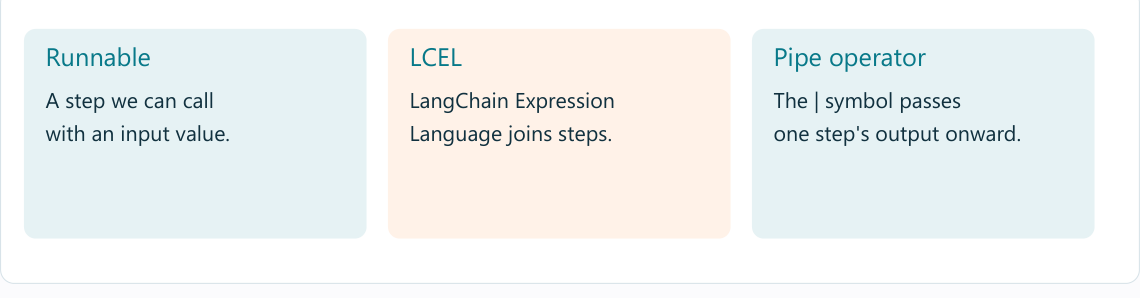

ChatOllama sends chat requests to the local Ollama server.

In [4]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [5]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [6]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

A chat prompt template fills named inputs and keeps message roles.

In [7]:
from langchain_core.prompts import ChatPromptTemplate

This parser reads reply content and returns a plain Python string.

In [8]:
from langchain_core.output_parsers import StrOutputParser

In [9]:
prompt = ChatPromptTemplate.from_template("Explain {topic} in three short points.")

The pipe sends prompt messages to the model, then sends its reply to a string parser.

In [10]:
chain = prompt | llm | StrOutputParser()

In [11]:
answer = chain.invoke({"topic": "Python lists"})
print(answer)

Here are three key points about Python lists:

1. **Dynamic Size**: Python lists are dynamic, meaning they can grow or shrink as elements are added or removed. This makes them ideal for storing collections of data that may change size.

2. **Ordered and Indexed**: Lists maintain the order in which elements were added and allow indexing (accessing specific elements by their position). This makes it easy to manipulate and access individual elements within a list.

3. **Mutability**: Python lists are mutable, meaning they can be modified after creation. This allows for efficient modification of existing data without having to create new lists or objects.


In [12]:
shorten = ChatPromptTemplate.from_template("Shorten this text to one sentence without adding facts: {text}") | llm | StrOutputParser()

A second stage uses the first reply. Read the intermediate answer so changes are visible.

In [13]:
print(shorten.invoke({"text": answer}))

Here is the text shortened to one sentence:

Python lists have several key characteristics that make them useful for storing and manipulating collections of data.


Try a fresh topic with the same chain.

In [14]:
print(chain.invoke({"topic": "Pandas tables"}))

Here are three short points explaining Pandas tables:

1. **Data Structure**: A Pandas table is a two-dimensional labeled data structure with columns of potentially different types. It's similar to an Excel spreadsheet or a SQL table, but with additional features like data manipulation and analysis capabilities.

2. **Column Alignment**: In a Pandas table, each column has a specific alignment (left, center, right) that determines how the values are displayed in the output. This alignment can be customized when printing or displaying the table.

3. **Customization Options**: Pandas tables offer various customization options, such as specifying the number of decimal places


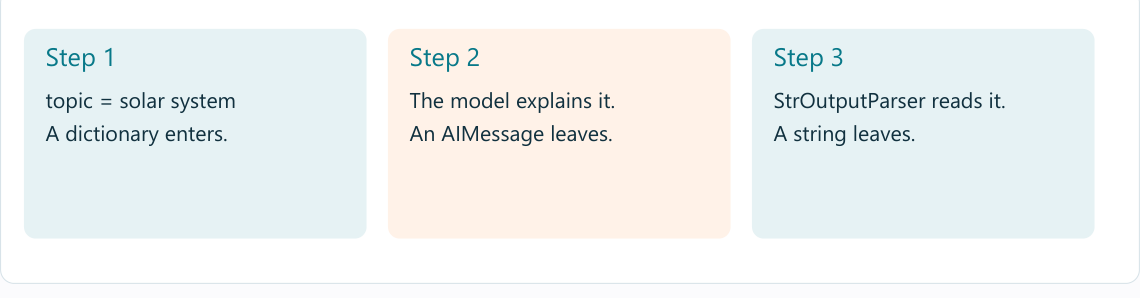

## Try a fresh input

Repeat with a new topic. Check whether the shorter text still keeps the same facts.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-chains).